# TP1 — Procesamiento de Imágenes | CEIA

**Parte 1:** algoritmo White Patch, resultados y análisis de fallas.  
**Parte 2:** histogramas en escala de grises y su utilidad como características para clasificación/detección.

**Ejecución:** Google Colab o Jupyter local. Ejecutar las celdas en orden. Se utiliza únicamente el material suministrado para el TP.

## Preparación de datos

En **Google Colab**, subí `TP1_datos.zip` cuando la primera celda lo solicite (o cargalo previamente desde el panel Archivos). Esta celda lo descomprime en `/content/TP1_datos`. En Jupyter local, ubicá `TP1_datos.zip` junto al notebook. También admite los tres archivos `white_patch.zip`, `img1_tp.png` e `img2_tp.png` subidos por separado.

In [ ]:
from pathlib import Path
import zipfile
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

BASE = Path('/content') if Path('/content').exists() else Path.cwd()
DATOS = BASE / 'TP1_datos'
DATOS.mkdir(parents=True, exist_ok=True)
ZIP_DATOS = BASE / 'TP1_datos.zip'

if ZIP_DATOS.exists():
    with zipfile.ZipFile(ZIP_DATOS) as z:
        z.extractall(DATOS)
else:
    zip_wp = BASE / 'white_patch.zip'
    if zip_wp.exists():
        with zipfile.ZipFile(zip_wp) as z:
            z.extractall(DATOS)
    for nombre in ('img1_tp.png', 'img2_tp.png'):
        origen = BASE / nombre
        if origen.exists():
            import shutil
            shutil.copy2(origen, DATOS / nombre)

faltantes = [n for n in ('img1_tp.png', 'img2_tp.png') if not (DATOS / n).exists()]
if faltantes or not list(DATOS.rglob('test_blue.png')):
    try:
        from google.colab import files
        print('Subí TP1_datos.zip desde tu equipo:')
        recibidos = files.upload()
        if 'TP1_datos.zip' not in recibidos:
            raise FileNotFoundError('Se requiere TP1_datos.zip')
        with zipfile.ZipFile(BASE / 'TP1_datos.zip') as z:
            z.extractall(DATOS)
    except ImportError:
        raise FileNotFoundError('Ubicá TP1_datos.zip junto al notebook y volvé a ejecutar.')

IMAGENES_WP = sorted(p for p in DATOS.rglob('*') if p.is_file() and p.suffix.lower() in ('.png','.jpg','.jpeg') and p.name.startswith(('test_','wp_')))
assert len(IMAGENES_WP) == 8, f'Se esperaban 8 imágenes White Patch; se encontraron {len(IMAGENES_WP)}: {IMAGENES_WP}'
assert all((DATOS / n).is_file() for n in ('img1_tp.png','img2_tp.png'))
print('Datos listos:', DATOS)
print('Imágenes White Patch:', [p.name for p in IMAGENES_WP])
print('Imágenes Parte 2: img1_tp.png, img2_tp.png')

Datos listos: /mnt/data/TP1_CEIA_REHECHO/TP1_datos
Imágenes White Patch: ['test_blue.png', 'test_green.png', 'test_red.png', 'wp_blue.jpg', 'wp_green.png', 'wp_green2.jpg', 'wp_red.png', 'wp_red2.jpg']
Imágenes Parte 2: img1_tp.png, img2_tp.png


## Parte 1 — White Patch

La hipótesis **White Patch** supone que cada canal contiene una referencia suficientemente brillante, idealmente blanca. Para cada canal $c \in \{R,G,B\}$ se calcula el máximo $M_c=\max_{x,y} I_c(x,y)$ y se aplica:

$$I'_c(x,y)=\operatorname{clip}\left(I_c(x,y)\frac{255}{M_c},0,255\right).$$

La corrección se realiza **por canal**, evitando dividir por cero. **Advertencia:** maximizar cada canal no garantiza una reproducción fiel de los colores; la hipótesis puede fallar si no hay referencias blancas, hay reflejos, saturación o ruido.

In [ ]:
def white_patch_rgb(imagen_rgb):
    """Corrección White Patch independiente para R, G y B."""
    x = imagen_rgb.astype(np.float32)
    maximos = x.max(axis=(0, 1))
    escalas = 255.0 / np.maximum(maximos, 1.0)
    salida = np.clip(x * escalas, 0, 255).astype(np.uint8)
    return salida, maximos, escalas

def cargar_rgb(ruta):
    bgr = cv2.imread(str(ruta), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f'No se pudo abrir {ruta}')
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# Prueba simple: un canal constante no debe generar división por cero.
prueba = np.zeros((3, 3, 3), dtype=np.uint8)
assert np.array_equal(white_patch_rgb(prueba)[0], prueba)
print('Implementación validada.')

Implementación validada.


### 1.1 Comparación visual: las ocho imágenes

Cada fila muestra la **imagen original** y la **corregida**; debajo se informan los máximos RGB y las escalas aplicadas. No se omite ninguna imagen.

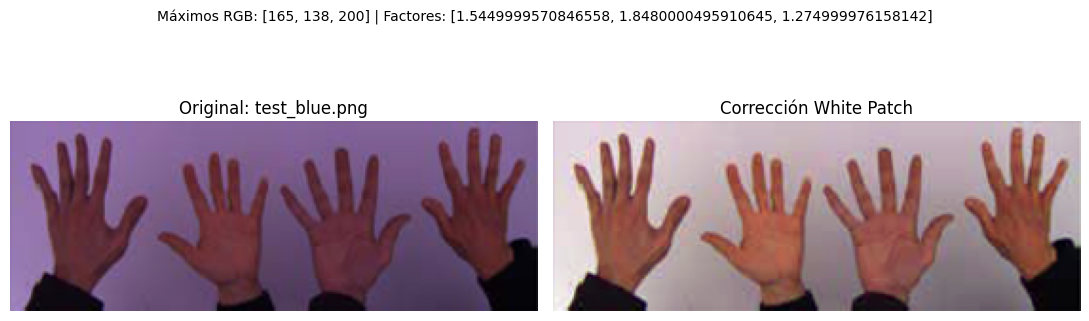

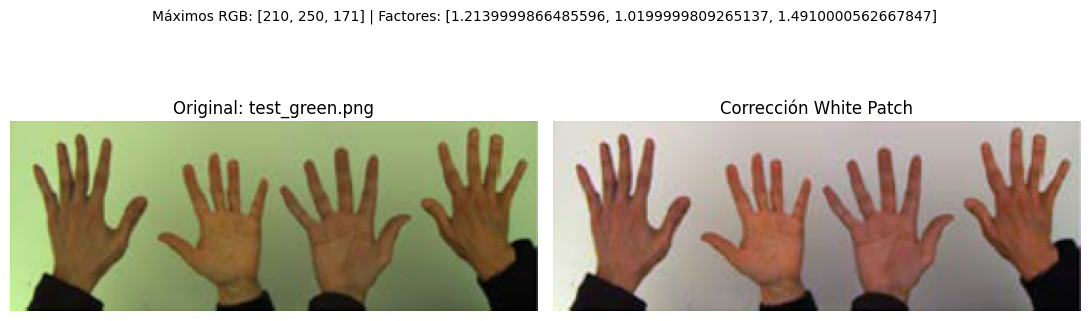

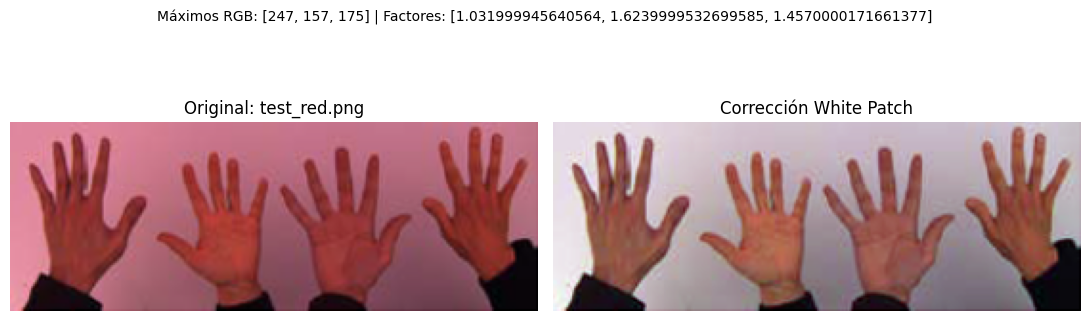

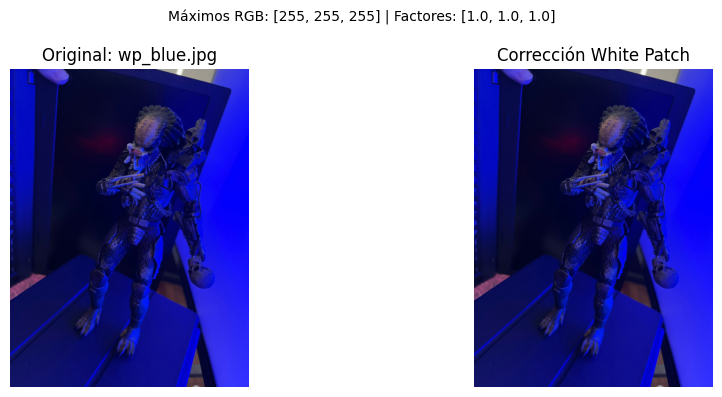

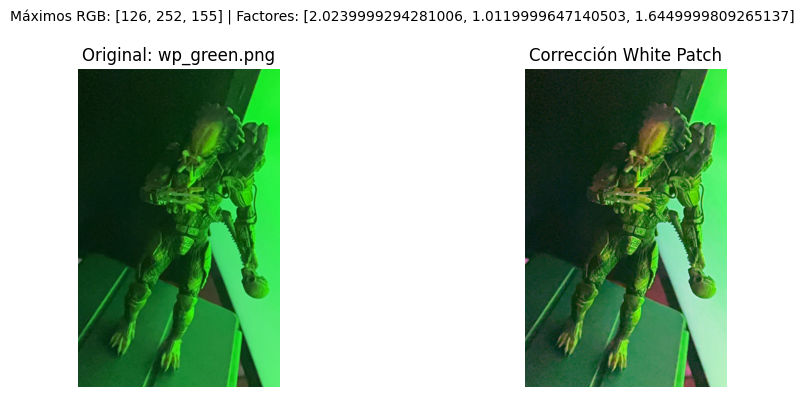

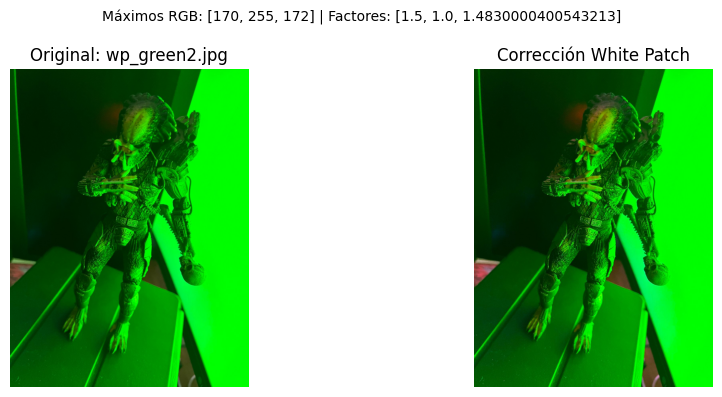

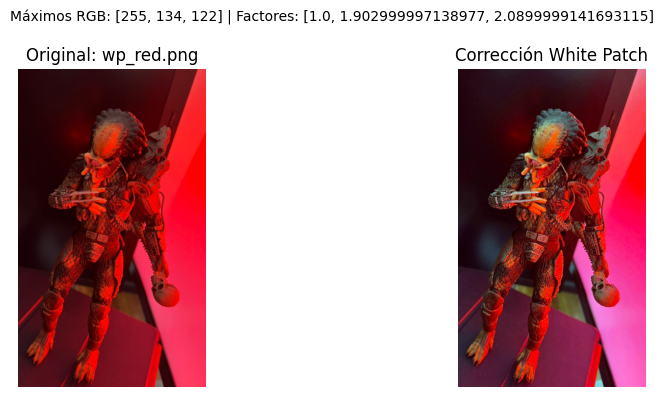

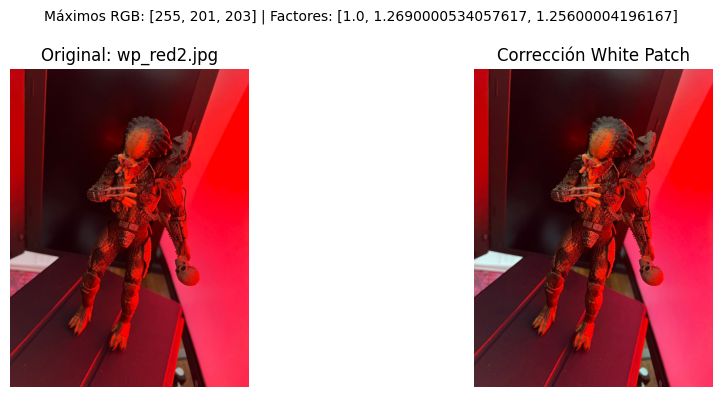

In [ ]:
resultados_wp = {}
for ruta in IMAGENES_WP:
    original = cargar_rgb(ruta)
    corregida, maximos, escalas = white_patch_rgb(original)
    resultados_wp[ruta.name] = (original, corregida, maximos, escalas)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].imshow(original)
    axes[0].set_title('Original: ' + ruta.name)
    axes[1].imshow(corregida)
    axes[1].set_title('Corrección White Patch')
    for ax in axes: ax.axis('off')
    fig.suptitle('Máximos RGB: {} | Factores: {}'.format(maximos.astype(int).tolist(), np.round(escalas, 3).tolist()), fontsize=10)
    plt.tight_layout()
    plt.show()

### 1.2 Histogramas RGB antes y después

Los histogramas muestran cómo se redistribuyen los niveles de intensidad de cada canal. Se grafican los tres canales por separado para facilitar la comparación.

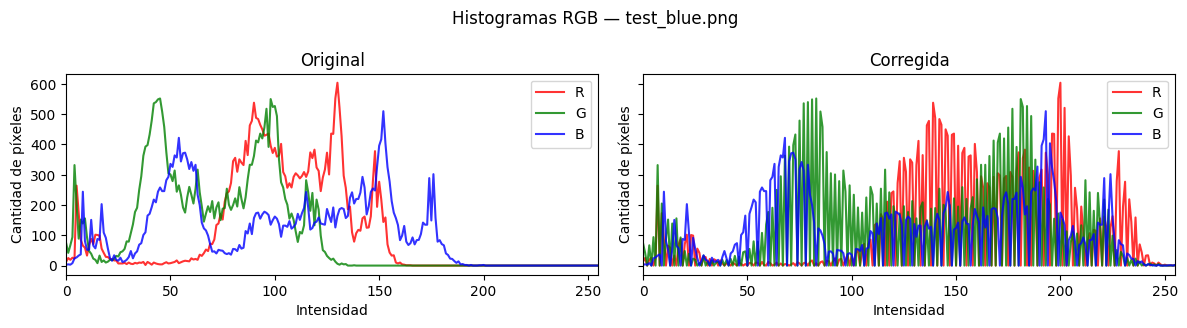

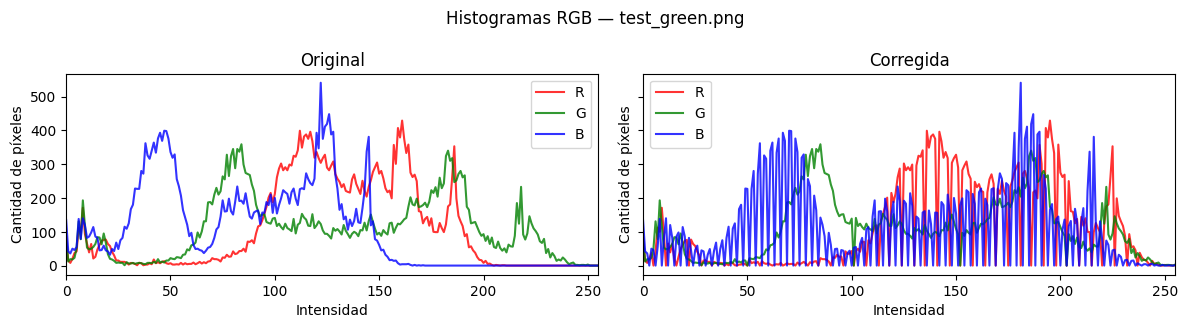

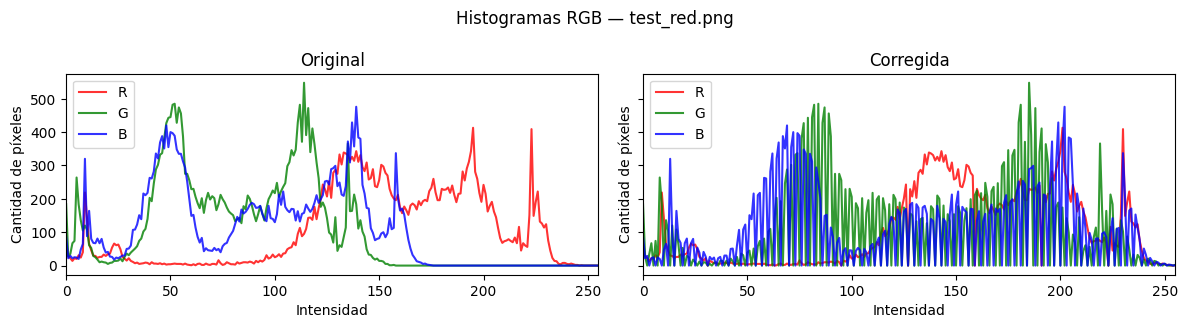

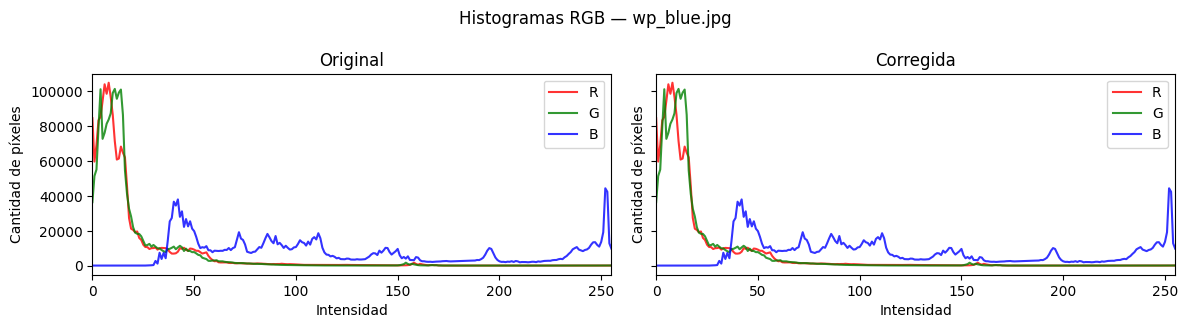

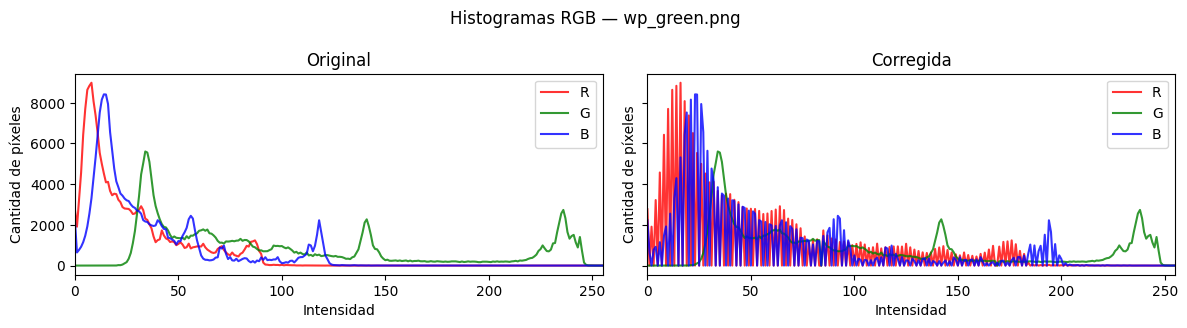

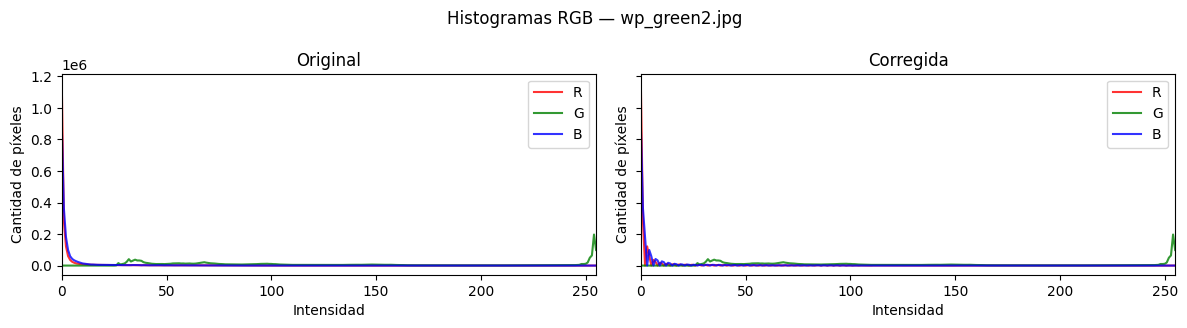

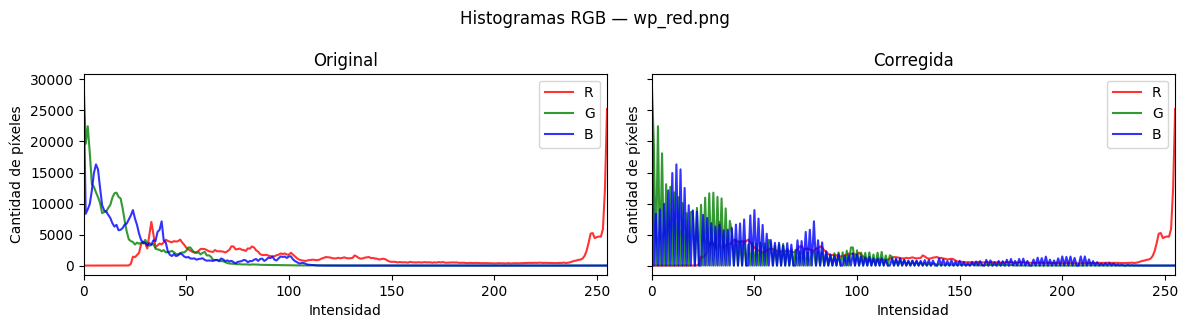

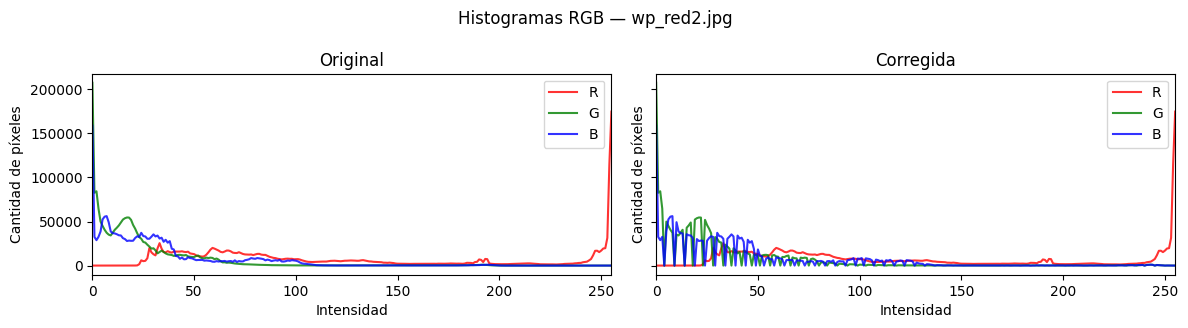

In [ ]:
for nombre, (original, corregida, _, _) in resultados_wp.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), sharey=True)
    for ax, img, titulo in zip(axes, (original, corregida), ('Original', 'Corregida')):
        for canal, color in enumerate(('red','green','blue')):
            hist = cv2.calcHist([img], [canal], None, [256], [0,256]).ravel()
            ax.plot(np.arange(256), hist, color=color, label='RGB'[canal], alpha=.8)
        ax.set_title(titulo)
        ax.set_xlim(0,255)
        ax.set_xlabel('Intensidad')
        ax.set_ylabel('Cantidad de píxeles')
        ax.legend()
    fig.suptitle('Histogramas RGB — ' + nombre)
    plt.tight_layout()
    plt.show()

### 1.3 Análisis crítico de White Patch

**Qué se observa:** al escalar independientemente los máximos de R, G y B, las dominantes de color pueden atenuarse y las superficies claras pueden acercarse a un tono neutro. La magnitud del cambio depende de los máximos de cada imagen; si un canal ya alcanza 255, su factor es 1.

**Posibles fallas:**

- **Ausencia de blanco real:** el máximo puede pertenecer a un objeto coloreado, introduciendo una dominante artificial.
- **Reflejos o píxeles atípicos:** un único valor extremo puede condicionar la corrección de todo el canal.
- **Saturación:** si hay canales recortados, no se recupera información perdida.
- **Escenas con iluminación no uniforme:** una única escala global por canal no corrige variaciones locales.
- **Ruido y cuantización:** el escalado puede amplificar ruido y producir redondeo en niveles de intensidad.

**Conclusión de la Parte 1:** White Patch es simple y computacionalmente económico, pero depende de una hipótesis fuerte sobre el contenido de la escena. Una mejora visual no constituye, por sí sola, una validación cuantitativa de fidelidad cromática. Para validar objetivamente se requeriría una referencia de color conocida.

## Parte 2 — Lectura de imágenes y análisis de histogramas

Se leen `img1_tp.png` e `img2_tp.png` **con OpenCV en escala de grises**, tal como pide la consigna.

Dimensiones: (288, 287) (288, 287)


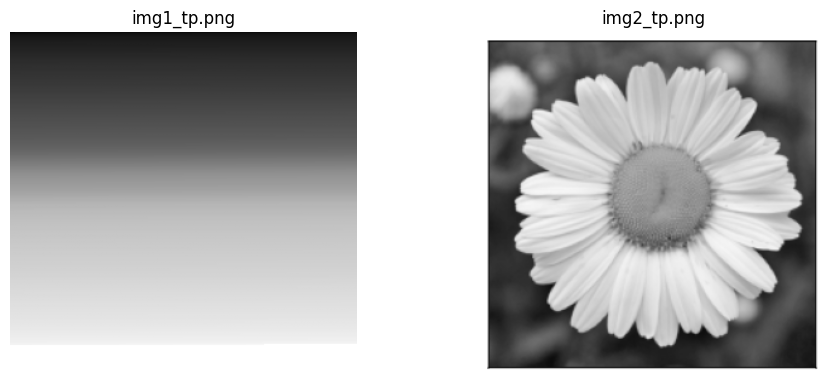

In [ ]:
img1 = cv2.imread(str(DATOS / 'img1_tp.png'), cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(str(DATOS / 'img2_tp.png'), cv2.IMREAD_GRAYSCALE)
assert img1 is not None and img2 is not None, 'No se pudieron cargar ambas imágenes.'
print('Dimensiones:', img1.shape, img2.shape)
fig, ax = plt.subplots(1, 2, figsize=(10,4))
for a, img, titulo in zip(ax, (img1,img2), ('img1_tp.png','img2_tp.png')):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(titulo)
    a.axis('off')
plt.tight_layout()
plt.show()

### 2.1 Elección del número de bins

Use **256 bins** como referencia, uno por nivel posible de gris en una imagen de 8 bits. Además comparamos **16 y 64 bins** para estudiar cómo el agrupamiento afecta la representación. Los histogramas se normalizan para que su suma sea 1.

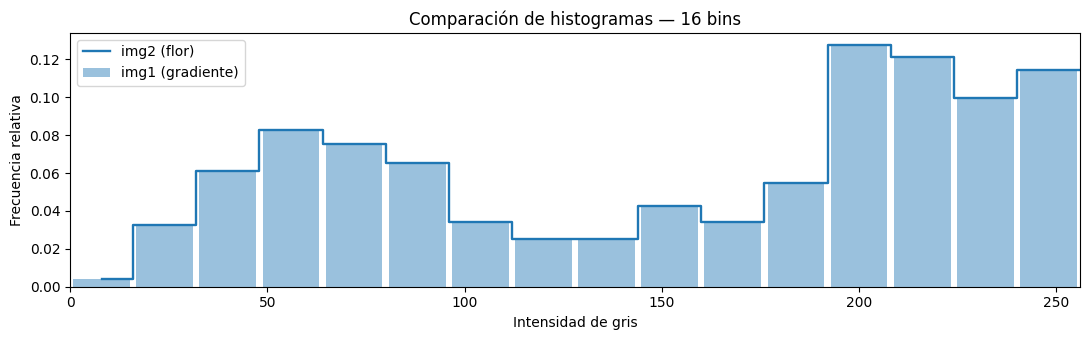

16 bins | histogramas idénticos: True | distancia L1: 0.000000


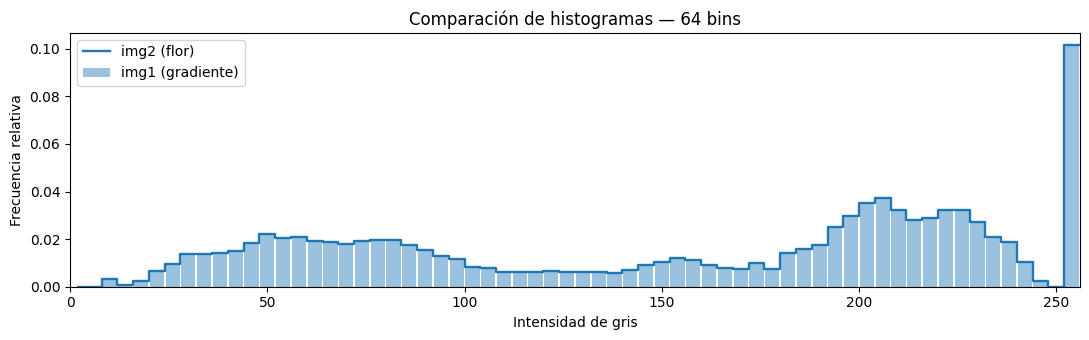

64 bins | histogramas idénticos: True | distancia L1: 0.000000


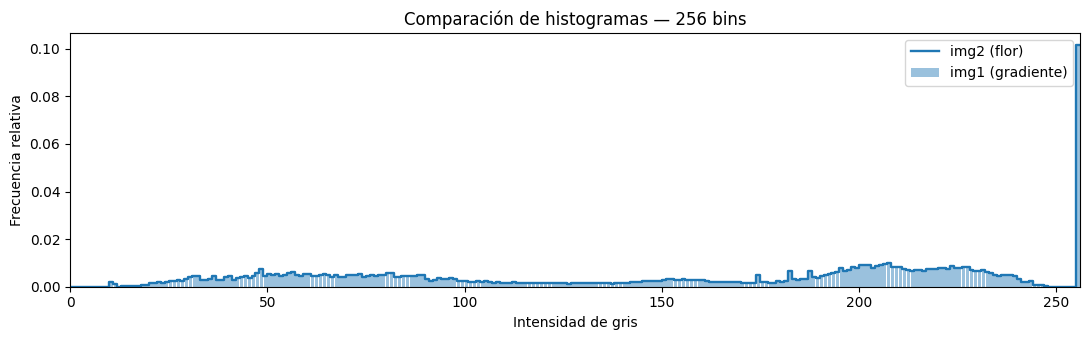

256 bins | histogramas idénticos: True | distancia L1: 0.000000


In [ ]:
def hist_normalizado(img, bins):
    h = cv2.calcHist([img], [0], None, [bins], [0,256]).ravel()
    return h / h.sum()

for bins in (16, 64, 256):
    h1, h2 = hist_normalizado(img1,bins), hist_normalizado(img2,bins)
    centros = (np.arange(bins)+.5)*256/bins
    ancho = 256/bins
    fig, ax = plt.subplots(figsize=(11,3.5))
    ax.bar(centros, h1, width=ancho*.9, alpha=.45, label='img1 (gradiente)')
    ax.step(np.r_[centros, 256], np.r_[h2,h2[-1]], where='mid', linewidth=1.7, label='img2 (flor)')
    ax.set(xlim=(0,256), xlabel='Intensidad de gris', ylabel='Frecuencia relativa', title=f'Comparación de histogramas — {bins} bins')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(f'{bins} bins | histogramas idénticos: {np.array_equal(h1,h2)} | distancia L1: {np.abs(h1-h2).sum():.6f}')

### 2.2 Comprobación y discusión

La comparación exacta de los histogramas de 256 bins determina si ambas imágenes contienen la misma cantidad de píxeles en cada nivel de gris. Esto es distinto de afirmar que las imágenes son iguales.

In [ ]:
h1_256 = np.bincount(img1.ravel(), minlength=256)
h2_256 = np.bincount(img2.ravel(), minlength=256)
print('¿Histogramas idénticos?', np.array_equal(h1_256,h2_256))
print('¿Imágenes idénticas píxel a píxel?', np.array_equal(img1,img2))
print('Cantidad de píxeles:', img1.size, img2.size)
print('Diferencia absoluta total entre histogramas:', int(np.abs(h1_256-h2_256).sum()))

¿Histogramas idénticos? True
¿Imágenes idénticas píxel a píxel? False
Cantidad de píxeles: 82656 82656
Diferencia absoluta total entre histogramas: 0


### 2.3 ¿Sirven los histogramas como features?

**Sí, pero con limitaciones.** Un histograma normalizado es un vector de longitud igual al número de bins y resume la distribución global de intensidades. Puede ser útil para tareas relacionadas con brillo, contraste o ciertas clases con perfiles tonales diferentes. También es relativamente barato de calcular.

**No alcanza para distinguir estructuras o localizar objetos:** el histograma descarta la posición de los píxeles. En estas dos imágenes, el histograma es idéntico aunque una representa un gradiente y la otra una flor. Un clasificador que reciba **únicamente** esos histogramas no podrá diferenciarlas; y un detector tampoco puede localizar la flor con esa información global.

**Alternativas complementarias:** histogramas por regiones, gradientes/HOG, texturas, descriptores locales o características aprendidas con redes convolucionales.

**Conclusión de la Parte 2:** elegir 256 bins preserva el detalle de las frecuencias por nivel; reducir bins suaviza la representación pero no recupera información espacial. La utilidad como feature depende de la tarea y debe validarse con datos de entrenamiento y prueba.

## Conclusión general

White Patch y los histogramas ilustran dos ideas centrales del procesamiento de imágenes: **la normalización fotométrica** puede reducir diferencias de iluminación bajo ciertos supuestos, y **los descriptores globales** pueden resumir una imagen perdiendo información relevante para el reconocimiento. Por ello, tanto la corrección cromática como la elección de características requieren considerar el objetivo y las limitaciones del método.

**Bibliotecas:** Python, NumPy, OpenCV y Matplotlib. **Datos:** imágenes suministradas con la consigna del TP1.